# Complaints: topics in the narratives

Real public data about real companies, exactly as the Consumer Financial Protection Bureau publishes it. The Bureau states its database is not a statistical sample of consumers' experiences in the marketplace.

> Harborline Bank is fictional. This is a demonstration on generated data and public datasets; no real customer, account or transaction of any real institution appears here.
>
> Nothing here is a credit decision, a fraud determination, a suspicious activity finding or investment advice.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from ledger_core.manifest import Manifest

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
m = Manifest.load(ROOT / "results" / "manifest.json")
plt.rcParams["figure.figsize"] = (9, 4)

In [2]:
topics = m.tables["f07.topics"]
pl.DataFrame(topics.rows, schema=topics.columns, orient="row")

Topic,Top terms,Complaints where it leads,Share,Of which form letters
i64,str,i64,f64,f64
1,"""fcra, reporting, inaccurate, a…",5118,0.11106,0.38941
2,"""money, called, bank, card, sen…",8116,0.176117,0.03758
3,"""theft, identity, fraudulent, v…",3584,0.077773,0.450335
4,"""debt, collection, validation, …",4581,0.099408,0.256058
5,"""late, payment, payments, paid,…",4234,0.091878,0.318611
6,"""section, consumer, usc, report…",4117,0.089339,0.659704
7,"""funds, transaction, despite, r…",6584,0.142873,0.13305
8,"""inquiries, unauthorized, hard,…",2445,0.053056,0.369325
9,"""balance, date, opened, number,…",1622,0.035197,0.168311


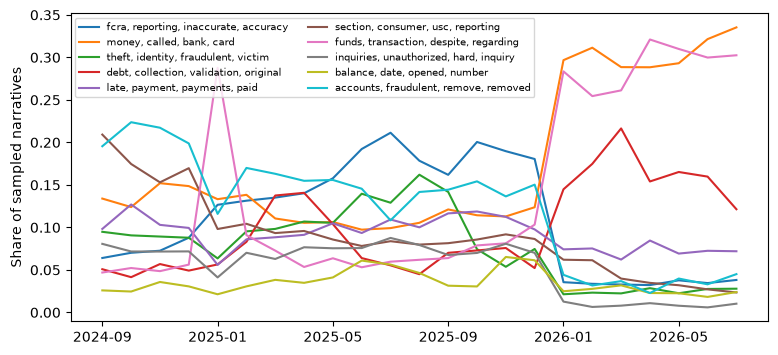

In [3]:
trend = pl.read_parquet(ROOT / "results" / "f07" / "topic_trend.parquet")
fig, ax = plt.subplots()
for t in sorted(trend["topic"].unique().to_list()):
    part = trend.filter(pl.col("topic") == t).sort("month")
    ax.plot(part["month"], part["share"], label=part["topic_label"][0])
ax.set_xticks(sorted(trend["month"].unique().to_list())[::4])
ax.legend(fontsize=7, ncol=2)
ax.set_ylabel("Share of sampled narratives")
plt.show()

In [4]:
print("Narratives that are form letters:", m.text("f07.template_share"))
print("Relief model:", m.text("models.relief.conclusion"), "| narrative adds", m.text("models.relief.narrative_gain"), "AUROC over the form")

Narratives that are form letters: 31.2%
Relief model: not approved | narrative adds 0.014 AUROC over the form
